In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:

import os
import pandas as pd
import numpy as np

# Explore the available dataset files
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


/kaggle/input/datasets/shashwatwork/consume-complaints-dataset-fo-nlp/complaints_processed.csv


In [2]:

import tensorflow as tf
import torch

print("TensorFlow:", tf.__version__)
print("PyTorch:", torch.__version__)
print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


TensorFlow: 2.21.0
PyTorch: 2.11.0+cu130
GPU Available: True
GPU: Tesla T4


In [3]:

import pandas as pd

# Load dataset
file_path = "/kaggle/input/datasets/shashwatwork/consume-complaints-dataset-fo-nlp/complaints_processed.csv"

df = pd.read_csv(file_path)

# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# First 5 records
display(df.head())

# Dataset information
print("\nDataset Info:")
df.info()

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicated rows
print("\nDuplicate Rows:", df.duplicated().sum())


Dataset Shape: (162421, 3)

Columns:
['Unnamed: 0', 'product', 'narrative']


,Unnamed: 0,product,narrative
0,0,credit_card,purchase order day shipping amount receive pro...
1,1,credit_card,forwarded message date tue subject please inve...
2,2,retail_banking,forwarded message cc sent friday pdt subject f...
3,3,credit_reporting,payment history missing credit report speciali...
4,4,credit_reporting,payment history missing credit report made mis...



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 162421 entries, 0 to 162420
Data columns (total 3 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   Unnamed: 0  162421 non-null  int64 
 1   product     162421 non-null  object
 2   narrative   162411 non-null  object
dtypes: int64(1), object(2)
memory usage: 3.7+ MB

Missing Values:
Unnamed: 0     0
product        0
narrative     10
dtype: int64

Duplicate Rows: 0


In [4]:

# Drop unnecessary index column
df = df.drop(columns=['Unnamed: 0'])

# Remove missing values
df = df.dropna(subset=['narrative'])

# Reset index
df = df.reset_index(drop=True)

print("Cleaned Dataset Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())

display(df.head())


Cleaned Dataset Shape: (162411, 2)

Missing Values:
product      0
narrative    0
dtype: int64


,product,narrative
0,credit_card,purchase order day shipping amount receive pro...
1,credit_card,forwarded message date tue subject please inve...
2,retail_banking,forwarded message cc sent friday pdt subject f...
3,credit_reporting,payment history missing credit report speciali...
4,credit_reporting,payment history missing credit report made mis...


Number of Classes: 5

Class Distribution:
product
credit_reporting       91172
debt_collection        23148
mortgages_and_loans    18990
credit_card            15566
retail_banking         13535
Name: count, dtype: int64

Text Length Statistics:
count    162411.000000
mean         80.232798
std         108.872213
min           1.000000
50%          50.000000
75%          95.000000
90%         168.000000
95%         240.000000
99%         525.000000
max        2685.000000
Name: text_length, dtype: float64


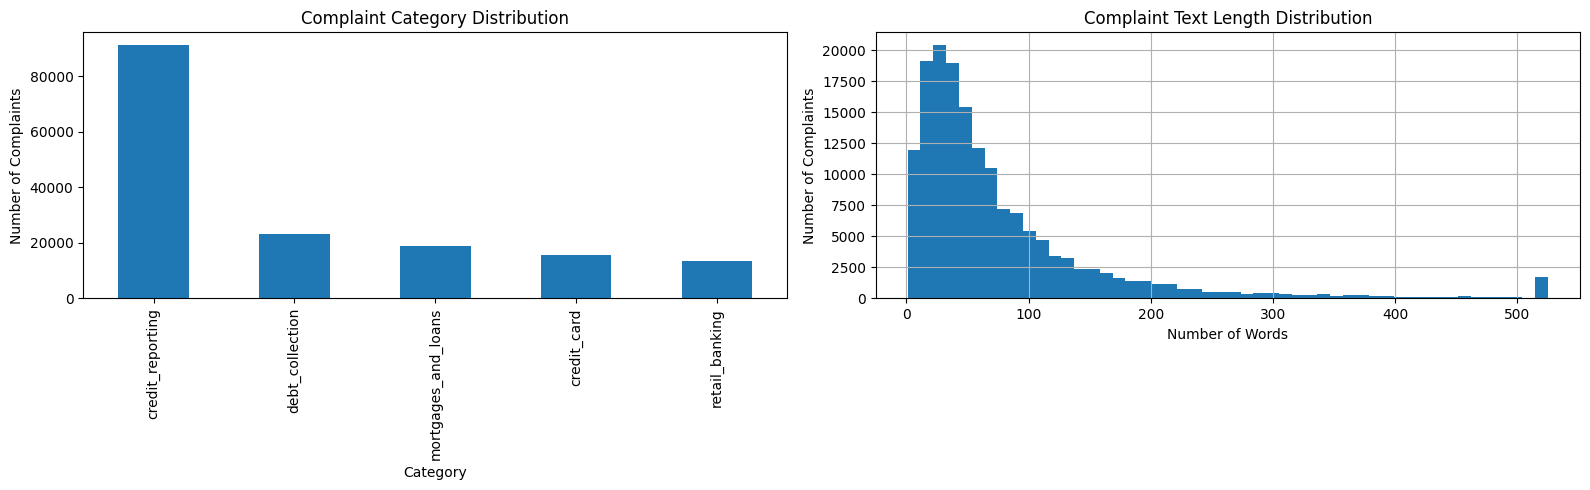

In [5]:

import matplotlib.pyplot as plt

# 1. Class Distribution
print("Number of Classes:", df['product'].nunique())
print("\nClass Distribution:")
print(df['product'].value_counts())

# 2. Text Length Analysis
df['text_length'] = df['narrative'].str.split().str.len()

print("\nText Length Statistics:")
print(
    df['text_length'].describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

# 3. Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

df['product'].value_counts().plot(
    kind='bar',
    ax=axes[0],
    title='Complaint Category Distribution'
)
axes[0].set_xlabel('Category')
axes[0].set_ylabel('Number of Complaints')

df['text_length'].clip(
    upper=df['text_length'].quantile(0.99)
).hist(bins=50, ax=axes[1])

axes[1].set_title('Complaint Text Length Distribution')
axes[1].set_xlabel('Number of Words')
axes[1].set_ylabel('Number of Complaints')

plt.tight_layout()
plt.show()


In [6]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Check duplicated complaint texts
print("Duplicate narratives:",
      df['narrative'].duplicated().sum())

# Check conflicting labels for identical texts
conflicting = (
    df.groupby('narrative')['product']
      .nunique()
)

print("Narratives with conflicting labels:",
      (conflicting > 1).sum())

# Remove exact duplicate narratives
# This keeps the first occurrence; label conflicts
# will be inspected before using the final dataset.


Duplicate narratives: 37939
Narratives with conflicting labels: 172


In [7]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Work on a copy
df_clean = df[['narrative', 'product']].copy()

# Remove blank or whitespace-only complaints
df_clean['narrative'] = df_clean['narrative'].astype(str).str.strip()
df_clean = df_clean[df_clean['narrative'].ne('')]

# Identify narratives associated with multiple labels
label_counts = df_clean.groupby('narrative')['product'].nunique()
conflict_texts = label_counts[label_counts > 1].index

# Save conflicting cases for inspection
df_conflicts = df_clean[
    df_clean['narrative'].isin(conflict_texts)
].copy()

df_conflicts.to_csv(
    '/kaggle/working/conflicting_complaints.csv',
    index=False
)

# Exclude all occurrences of conflicting narratives
df_clean = df_clean[
    ~df_clean['narrative'].isin(conflict_texts)
].copy()

# Keep one occurrence of each consistent narrative
df_clean = df_clean.drop_duplicates(
    subset=['narrative']
).reset_index(drop=True)

print("Original records:", len(df))
print("Conflicting unique narratives:", len(conflict_texts))
print("Records in clean dataset:", len(df_clean))
print("Remaining duplicate narratives:",
      df_clean['narrative'].duplicated().sum())

print("\nClass Distribution:")
print(df_clean['product'].value_counts())


Original records: 162411
Conflicting unique narratives: 172
Records in clean dataset: 124300
Remaining duplicate narratives: 0

Class Distribution:
product
credit_reporting       56172
debt_collection        20998
mortgages_and_loans    18701
credit_card            14963
retail_banking         13466
Name: count, dtype: int64


In [8]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Encode categories
label_encoder = LabelEncoder()
df_clean['label'] = label_encoder.fit_transform(df_clean['product'])

num_classes = len(label_encoder.classes_)

print("Label Mapping:")
for i, category in enumerate(label_encoder.classes_):
    print(f"{i} -> {category}")

# 80% Training / 10% Validation / 10% Testing
train_df, temp_df = train_test_split(
    df_clean,
    test_size=0.20,
    random_state=42,
    stratify=df_clean['label']
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df['label']
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("\nDataset Split:")
print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

# Verify no leakage
assert set(train_df['narrative']).isdisjoint(set(val_df['narrative']))
assert set(train_df['narrative']).isdisjoint(set(test_df['narrative']))
assert set(val_df['narrative']).isdisjoint(set(test_df['narrative']))

print("\nNo duplicate narrative leakage detected!")

# Save the splits
train_df.to_csv('/kaggle/working/train.csv', index=False)
val_df.to_csv('/kaggle/working/val.csv', index=False)
test_df.to_csv('/kaggle/working/test.csv', index=False)


Label Mapping:
0 -> credit_card
1 -> credit_reporting
2 -> debt_collection
3 -> mortgages_and_loans
4 -> retail_banking

Dataset Split:
Training: (99440, 3)
Validation: (12430, 3)
Testing: (12430, 3)

No duplicate narrative leakage detected!


In [17]:

import numpy as np
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Reproducibility
SEED = 42
tf.keras.utils.set_random_seed(SEED)

# Hyperparameters
MAX_WORDS = 20000
MAX_LEN = 240
EMBEDDING_DIM = 128
BATCH_SIZE = 128
EPOCHS = 100

print("TensorFlow Version:", tf.__version__)
print("Vocabulary Size:", MAX_WORDS)
print("Maximum Sequence Length:", MAX_LEN)
print("Embedding Dimension:", EMBEDDING_DIM)


TensorFlow Version: 2.21.0
Vocabulary Size: 20000
Maximum Sequence Length: 240
Embedding Dimension: 128


In [18]:

# Extract text from splits
X_train_text = train_df['narrative'].astype(str).tolist()
X_val_text = val_df['narrative'].astype(str).tolist()
X_test_text = test_df['narrative'].astype(str).tolist()

# Initialize tokenizer
tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

# Fit ONLY on training data to avoid leakage
tokenizer.fit_on_texts(X_train_text)

# Convert texts to integer sequences
X_train_seq = tokenizer.texts_to_sequences(X_train_text)
X_val_seq = tokenizer.texts_to_sequences(X_val_text)
X_test_seq = tokenizer.texts_to_sequences(X_test_text)

print("Vocabulary Size:", len(tokenizer.word_index))
print("\nOriginal Text:")
print(X_train_text[0][:250])

print("\nTokenized Sequence:")
print(X_train_seq[0][:30])


Vocabulary Size: 41669

Original Text:
first problem resolved reporting reliacard stolen problem getting thru realrep due call frauded rep know infor hey know told last rep self needed send online review told never received rep dame page response know talking real act inactive due unable 

Tokenized Sequence:
[113, 206, 356, 14, 1976, 557, 206, 266, 951, 1, 26, 21, 7201, 352, 90, 11560, 3623, 90, 18, 114, 352, 1961, 231, 109, 144, 320, 18, 20, 16, 352]


In [19]:

X_train = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding='post',
    truncating='post'
)

X_val = pad_sequences(
    X_val_seq,
    maxlen=MAX_LEN,
    padding='post',
    truncating='post'
)

X_test = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding='post',
    truncating='post'
)

# Target labels
y_train = train_df['label'].to_numpy()
y_val = val_df['label'].to_numpy()
y_test = test_df['label'].to_numpy()

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("\nExample Padded Sequence:")
print(X_train[0][:40])


X_train: (99440, 240)
X_val: (12430, 240)
X_test: (12430, 240)

Example Padded Sequence:
[  113   206   356    14  1976   557   206   266   951     1    26    21
  7201   352    90 11560  3623    90    18   114   352  1961   231   109
   144   320    18    20    16   352 13797   548    91    90  1052   703
    93  3218    26   263]


In [20]:

from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("Class Weights:\n")

for cls, weight in class_weights.items():
    print(
        f"{label_encoder.inverse_transform([cls])[0]}: "
        f"{weight:.4f}"
    )


Class Weights:

credit_card: 1.6615
credit_reporting: 0.4426
debt_collection: 1.1840
mortgages_and_loans: 1.3293
retail_banking: 1.8461


In [21]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Embedding, SimpleRNN, Dense, Dropout
)
from tensorflow.keras.optimizers import Adam

simple_rnn_model = Sequential([
    Input(shape=(MAX_LEN,)),

    Embedding(
        input_dim=MAX_WORDS,
        output_dim=EMBEDDING_DIM,
        mask_zero=True
    ),

    SimpleRNN(
        units=64
    ),

    Dropout(0.3),

    Dense(
        units=64,
        activation='relu'
    ),

    Dense(
        units=num_classes,
        activation='softmax'
    )
], name="SimpleRNN_Classifier")

simple_rnn_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

simple_rnn_model.summary()


Model: "SimpleRNN_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 240, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,576,837 (9.83 MB)

 Trainable params: 2,576,837 (9.83 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

simple_rnn_callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        filepath='/kaggle/working/artifacts/simple_rnn_best.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]


**# Simple RNN Training**

In [23]:

import time

start_time = time.time()

simple_rnn_history = simple_rnn_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=simple_rnn_callbacks,
    verbose=1
)

simple_rnn_training_time = time.time() - start_time

print(
    f"Training Time: "
    f"{simple_rnn_training_time / 60:.2f} minutes"
)


Epoch 1/100
777/777 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.5403 - loss: 1.1782
Epoch 1: val_loss improved from None to 1.35328, saving model to /kaggle/working/artifacts/simple_rnn_best.keras

Epoch 1: finished saving model to /kaggle/working/artifacts/simple_rnn_best.keras
777/777 ━━━━━━━━━━━━━━━━━━━━ 23s 26ms/step - accuracy: 0.6084 - loss: 1.0342 - val_accuracy: 0.4110 - val_loss: 1.3533 - learning_rate: 0.0010
Epoch 2/100
775/777 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.5719 - loss: 1.0761
Epoch 2: val_loss did not improve from 1.35328
777/777 ━━━━━━━━━━━━━━━━━━━━ 18s 23ms/step - accuracy: 0.5740 - loss: 1.0690 - val_accuracy: 0.3856 - val_loss: 1.7260 - learning_rate: 0.0010
Epoch 3/100
775/777 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.4708 - loss: 1.2932
Epoch 3: val_loss improved from 1.35328 to 0.89225, saving model to /kaggle/working/artifacts/simple_rnn_best.keras

Epoch 3: finished saving model to /kaggle/working/artifacts/simple_rnn_best.keras
777/777 

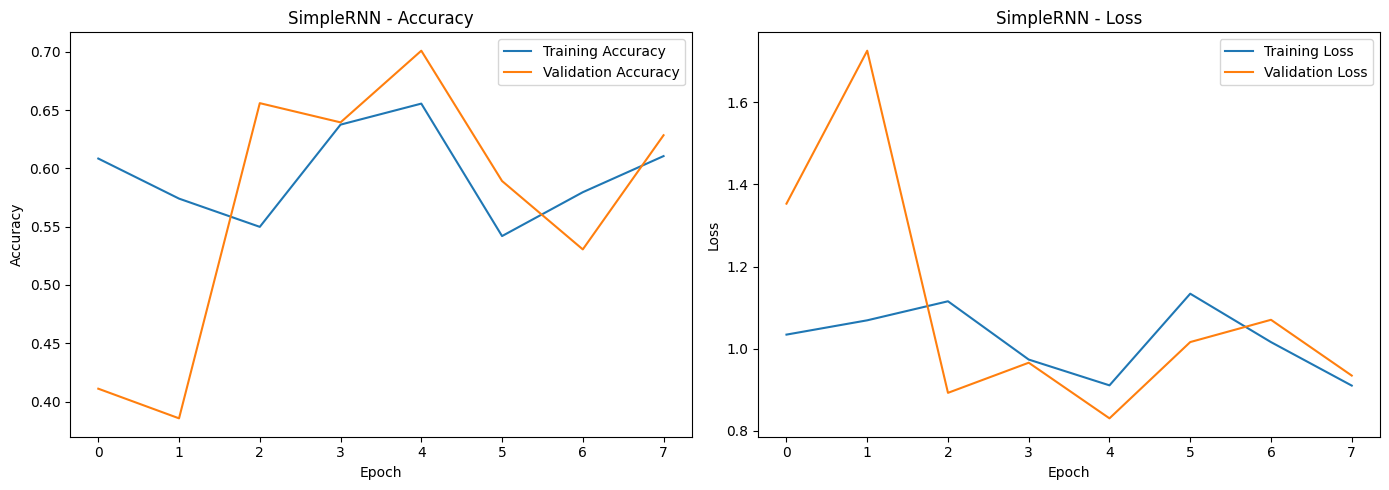

In [24]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(
    simple_rnn_history.history['accuracy'],
    label='Training Accuracy'
)
axes[0].plot(
    simple_rnn_history.history['val_accuracy'],
    label='Validation Accuracy'
)
axes[0].set_title('SimpleRNN - Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

# Loss
axes[1].plot(
    simple_rnn_history.history['loss'],
    label='Training Loss'
)
axes[1].plot(
    simple_rnn_history.history['val_loss'],
    label='Validation Loss'
)
axes[1].set_title('SimpleRNN - Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()

plt.tight_layout()
plt.show()


In [25]:

import tensorflow as tf
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Load best saved checkpoint
best_simple_rnn = tf.keras.models.load_model(
    "/kaggle/working/artifacts/simple_rnn_best.keras",
    compile=False
)

# Predict validation data
val_probs = best_simple_rnn.predict(
    X_val,
    batch_size=128,
    verbose=1
)

val_preds = np.argmax(val_probs, axis=1)

# Calculate metrics
val_accuracy = accuracy_score(y_val, val_preds)
val_macro_f1 = f1_score(
    y_val,
    val_preds,
    average="macro",
    zero_division=0
)

print("\nSimpleRNN - Validation Results")
print("-" * 40)
print(f"Accuracy: {val_accuracy:.4f}")
print(f"Macro F1: {val_macro_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        val_preds,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)


98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step

SimpleRNN - Validation Results
----------------------------------------
Accuracy: 0.7009
Macro F1: 0.6931

Classification Report:
                     precision    recall  f1-score   support

        credit_card       0.58      0.69      0.63      1496
   credit_reporting       0.88      0.64      0.74      5617
    debt_collection       0.51      0.74      0.61      2100
mortgages_and_loans       0.71      0.83      0.76      1870
     retail_banking       0.73      0.72      0.72      1347

           accuracy                           0.70     12430
          macro avg       0.68      0.72      0.69     12430
       weighted avg       0.74      0.70      0.71     12430



98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step
SimpleRNN Test Results
----------------------------------------
Accuracy:  0.6926
Precision: 0.6746
Recall:    0.7207
Macro F1:  0.6875

Classification Report:
                     precision    recall  f1-score   support

        credit_card       0.58      0.68      0.62      1497
   credit_reporting       0.87      0.63      0.73      5617
    debt_collection       0.50      0.73      0.59      2100
mortgages_and_loans       0.70      0.83      0.76      1870
     retail_banking       0.72      0.74      0.73      1346

           accuracy                           0.69     12430
          macro avg       0.67      0.72      0.69     12430
       weighted avg       0.73      0.69      0.70     12430



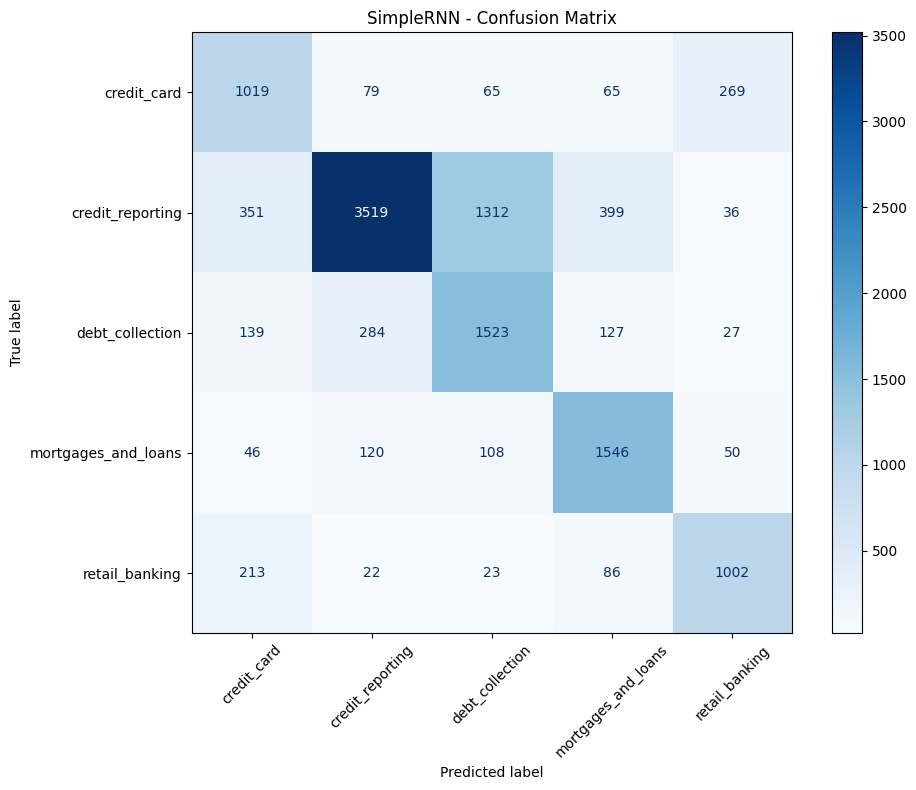

In [26]:

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Load best checkpoint
simple_rnn_model = tf.keras.models.load_model(
    '/kaggle/working/artifacts/simple_rnn_best.keras'
)

# Predict
simple_rnn_probs = simple_rnn_model.predict(
    X_test,
    batch_size=BATCH_SIZE
)

simple_rnn_preds = np.argmax(simple_rnn_probs, axis=1)

# Metrics
simple_rnn_accuracy = accuracy_score(
    y_test, simple_rnn_preds
)

simple_rnn_precision, simple_rnn_recall, simple_rnn_f1, _ = (
    precision_recall_fscore_support(
        y_test,
        simple_rnn_preds,
        average='macro',
        zero_division=0
    )
)

print("SimpleRNN Test Results")
print("-" * 40)
print(f"Accuracy:  {simple_rnn_accuracy:.4f}")
print(f"Precision: {simple_rnn_precision:.4f}")
print(f"Recall:    {simple_rnn_recall:.4f}")
print(f"Macro F1:  {simple_rnn_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        simple_rnn_preds,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

# Confusion Matrix
cm = confusion_matrix(y_test, simple_rnn_preds)

fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
).plot(
    ax=ax,
    cmap='Blues',
    xticks_rotation=45,
    values_format='d'
)

plt.title('SimpleRNN - Confusion Matrix')
plt.tight_layout()
plt.show()


In [27]:

import pandas as pd

model_results = []

model_results.append({
    'Model': 'SimpleRNN',
    'Accuracy': simple_rnn_accuracy,
    'Macro Precision': simple_rnn_precision,
    'Macro Recall': simple_rnn_recall,
    'Macro F1': simple_rnn_f1,
    'Training Time (min)': simple_rnn_training_time / 60
})

results_df = pd.DataFrame(model_results)

display(results_df)

results_df.to_csv(
    '/kaggle/working/artifacts/model_comparison.csv',
    index=False
)


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Training Time (min)
0,SimpleRNN,0.692599,0.674556,0.720718,0.68747,2.446933


In [28]:

import pandas as pd
import os

comparison_path = (
    "/kaggle/working/artifacts/"
    "validation_model_comparison.csv"
)

simple_rnn_result = pd.DataFrame([{
    "Model": "SimpleRNN",
    "Validation Accuracy": val_accuracy,
    "Validation Macro F1": val_macro_f1,
    "Training Time (min)": simple_rnn_training_time / 60,
    "Checkpoint": (
        "/kaggle/working/artifacts/"
        "simple_rnn_best.keras"
    )
}])

simple_rnn_result.to_csv(
    comparison_path,
    index=False
)

display(simple_rnn_result)


,Model,Validation Accuracy,Validation Macro F1,Training Time (min),Checkpoint
0,SimpleRNN,0.700885,0.693135,2.446933,/kaggle/working/artifacts/simple_rnn_best.keras


**LSTM**

In [29]:

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

# Clear previous model graph
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

lstm_model = Sequential([
    Input(shape=(MAX_LEN,)),

    Embedding(
        input_dim=MAX_WORDS,
        output_dim=EMBEDDING_DIM,
        mask_zero=True
    ),

    LSTM(
        units=64
    ),

    Dropout(0.3),

    Dense(
        units=64,
        activation='relu'
    ),

    Dense(
        units=num_classes,
        activation='softmax'
    )
], name="LSTM_Classifier")

lstm_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

lstm_model.summary()


Model: "LSTM_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 240, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,613,893 (9.97 MB)

 Trainable params: 2,613,893 (9.97 MB)

 Non-trainable params: 0 (0.00 B)

In [30]:

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

lstm_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        filepath="/kaggle/working/artifacts/lstm_best.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]


**Train LSTM**

In [31]:

import time

start_time = time.time()

lstm_history = lstm_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=lstm_callbacks,
    verbose=1
)

lstm_training_time = time.time() - start_time

print(
    f"LSTM Training Time: "
    f"{lstm_training_time / 60:.2f} minutes"
)


Epoch 1/100
775/777 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6390 - loss: 0.9728
Epoch 1: val_loss improved from None to 0.62906, saving model to /kaggle/working/artifacts/lstm_best.keras

Epoch 1: finished saving model to /kaggle/working/artifacts/lstm_best.keras
777/777 ━━━━━━━━━━━━━━━━━━━━ 17s 16ms/step - accuracy: 0.7319 - loss: 0.7745 - val_accuracy: 0.8041 - val_loss: 0.6291 - learning_rate: 0.0010
Epoch 2/100
776/777 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8072 - loss: 0.5850
Epoch 2: val_loss improved from 0.62906 to 0.61804, saving model to /kaggle/working/artifacts/lstm_best.keras

Epoch 2: finished saving model to /kaggle/working/artifacts/lstm_best.keras
777/777 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - accuracy: 0.8093 - loss: 0.5668 - val_accuracy: 0.7992 - val_loss: 0.6180 - learning_rate: 0.0010
Epoch 3/100
776/777 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8293 - loss: 0.4861
Epoch 3: val_loss improved from 0.61804 to 0.58593, saving model to /kaggle/wor

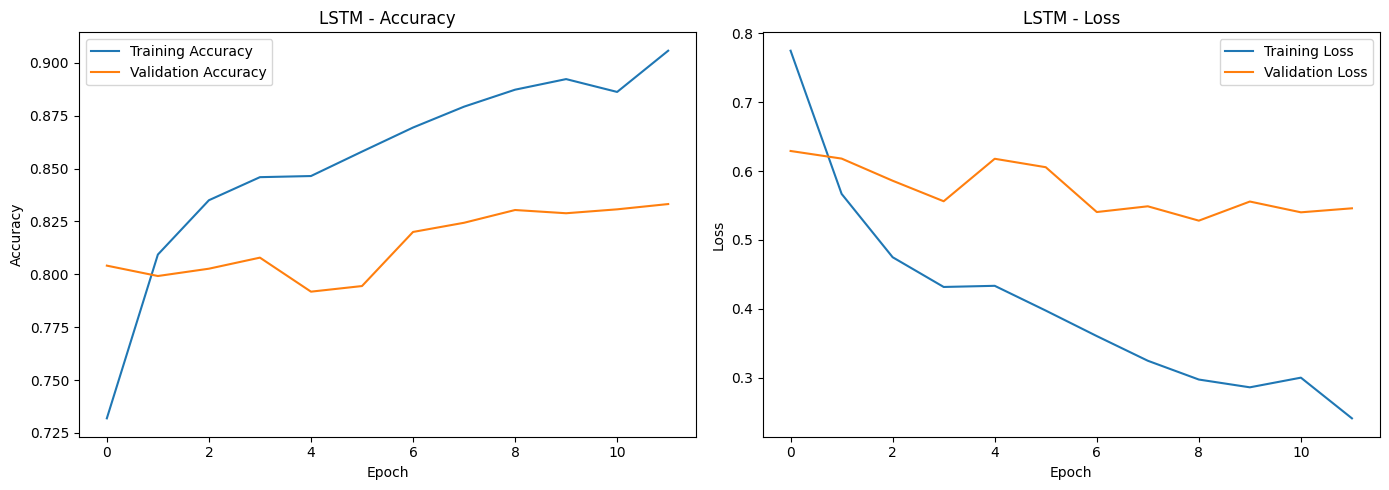

In [32]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    lstm_history.history['accuracy'],
    label='Training Accuracy'
)
axes[0].plot(
    lstm_history.history['val_accuracy'],
    label='Validation Accuracy'
)
axes[0].set_title('LSTM - Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

axes[1].plot(
    lstm_history.history['loss'],
    label='Training Loss'
)
axes[1].plot(
    lstm_history.history['val_loss'],
    label='Validation Loss'
)
axes[1].set_title('LSTM - Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()

plt.tight_layout()
plt.show()


98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
LSTM Validation Results
----------------------------------------
Accuracy:  0.8304
Precision: 0.8002
Recall:    0.8345
Macro F1:  0.8154

Classification Report:
                     precision    recall  f1-score   support

        credit_card       0.73      0.80      0.76      1496
   credit_reporting       0.92      0.82      0.87      5617
    debt_collection       0.74      0.84      0.78      2100
mortgages_and_loans       0.81      0.84      0.83      1870
     retail_banking       0.80      0.87      0.83      1347

           accuracy                           0.83     12430
          macro avg       0.80      0.83      0.82     12430
       weighted avg       0.84      0.83      0.83     12430



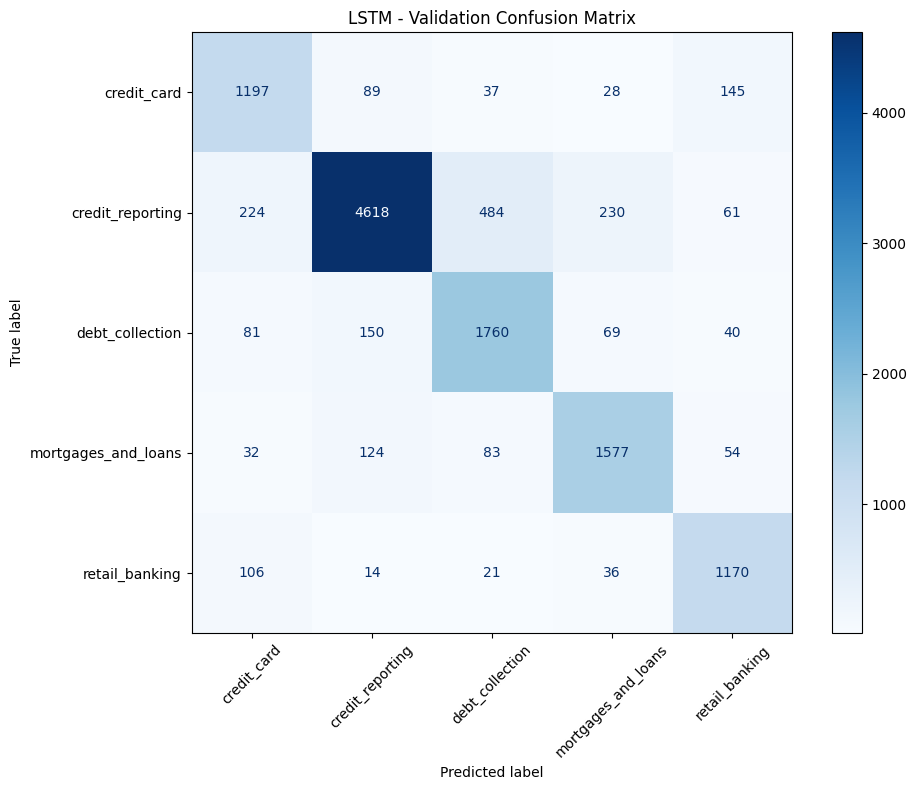

In [33]:

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Load best checkpoint
best_lstm = tf.keras.models.load_model(
    "/kaggle/working/artifacts/lstm_best.keras",
    compile=False
)

lstm_val_probs = best_lstm.predict(
    X_val,
    batch_size=BATCH_SIZE,
    verbose=1
)

lstm_val_preds = np.argmax(lstm_val_probs, axis=1)

lstm_val_accuracy = accuracy_score(y_val, lstm_val_preds)
lstm_val_precision = precision_score(
    y_val, lstm_val_preds, average="macro", zero_division=0
)
lstm_val_recall = recall_score(
    y_val, lstm_val_preds, average="macro", zero_division=0
)
lstm_val_macro_f1 = f1_score(
    y_val, lstm_val_preds, average="macro", zero_division=0
)

print("LSTM Validation Results")
print("-" * 40)
print(f"Accuracy:  {lstm_val_accuracy:.4f}")
print(f"Precision: {lstm_val_precision:.4f}")
print(f"Recall:    {lstm_val_recall:.4f}")
print(f"Macro F1:  {lstm_val_macro_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        lstm_val_preds,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

cm = confusion_matrix(y_val, lstm_val_preds)

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
).plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("LSTM - Validation Confusion Matrix")
plt.tight_layout()
plt.show()


In [36]:

import os
import pandas as pd

comparison_path = (
    "/kaggle/working/artifacts/"
    "validation_model_comparison.csv"
)

lstm_result = pd.DataFrame([{
    "Model": "LSTM",
    "Validation Accuracy": lstm_val_accuracy,
    "Validation Macro F1": lstm_val_macro_f1,
    "Training Time (min)": lstm_training_time / 60,
    "Checkpoint": "/kaggle/working/artifacts/lstm_best.keras"
}])

if os.path.exists(comparison_path):
    previous_results = pd.read_csv(comparison_path)
    comparison_df = pd.concat(
        [previous_results, lstm_result],
        ignore_index=True
    )
    comparison_df = comparison_df.drop_duplicates(
        subset=["Model"],
        keep="last"
    )
else:
    comparison_df = lstm_result

comparison_df.to_csv(comparison_path, index=False)

display(
    comparison_df.sort_values(
        "Validation Macro F1",
        ascending=False
    )
)


,Model,Validation Accuracy,Validation Macro F1,Training Time (min),Checkpoint
2,LSTM,0.830410,0.815412,2.378259,/kaggle/working/artifacts/lstm_best.keras
0,SimpleRNN,0.700885,0.693135,2.446933,/kaggle/working/artifacts/simple_rnn_best.keras


**GRU Model**

In [37]:

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, GRU, Dense, Dropout
from tensorflow.keras.optimizers import Adam

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

gru_model = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(
        input_dim=MAX_WORDS,
        output_dim=EMBEDDING_DIM,
        mask_zero=True
    ),
    GRU(64),
    Dropout(0.3),
    Dense(64, activation="relu"),
    Dense(num_classes, activation="softmax")
], name="GRU_Classifier")

gru_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

gru_model.summary()


Model: "GRU_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 240, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        37,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,601,733 (9.92 MB)

 Trainable params: 2,601,733 (9.92 MB)

 Non-trainable params: 0 (0.00 B)

In [38]:

from tensorflow.keras.callbacks import (
    EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
)

gru_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        "/kaggle/working/artifacts/gru_best.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]


In [39]:

import time

start_time = time.time()

gru_history = gru_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=gru_callbacks,
    verbose=1
)

gru_training_time = (time.time() - start_time) / 60
print(f"GRU Training Time: {gru_training_time:.2f} min")


Epoch 1/100
777/777 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5993 - loss: 0.9781
Epoch 1: val_loss improved from None to 0.49886, saving model to /kaggle/working/artifacts/gru_best.keras

Epoch 1: finished saving model to /kaggle/working/artifacts/gru_best.keras
777/777 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - accuracy: 0.7354 - loss: 0.6971 - val_accuracy: 0.8294 - val_loss: 0.4989 - learning_rate: 0.0010
Epoch 2/100
776/777 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8357 - loss: 0.4472
Epoch 2: val_loss improved from 0.49886 to 0.48874, saving model to /kaggle/working/artifacts/gru_best.keras

Epoch 2: finished saving model to /kaggle/working/artifacts/gru_best.keras
777/777 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.8420 - loss: 0.4288 - val_accuracy: 0.8281 - val_loss: 0.4887 - learning_rate: 0.0010
Epoch 3/100
775/777 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8560 - loss: 0.3818
Epoch 3: val_loss did not improve from 0.48874
777/777 ━━━━━━━━━━━━━━━━━━━━ 11s 14m

In [40]:

import numpy as np
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report
)

best_gru = tf.keras.models.load_model(
    "/kaggle/working/artifacts/gru_best.keras",
    compile=False
)

gru_val_probs = best_gru.predict(
    X_val, batch_size=BATCH_SIZE, verbose=1
)
gru_val_preds = np.argmax(gru_val_probs, axis=1)

gru_val_accuracy = accuracy_score(y_val, gru_val_preds)
gru_val_precision = precision_score(
    y_val, gru_val_preds, average="macro", zero_division=0
)
gru_val_recall = recall_score(
    y_val, gru_val_preds, average="macro", zero_division=0
)
gru_val_macro_f1 = f1_score(
    y_val, gru_val_preds, average="macro", zero_division=0
)

print("GRU Validation Results")
print(f"Accuracy: {gru_val_accuracy:.4f}")
print(f"Precision: {gru_val_precision:.4f}")
print(f"Recall: {gru_val_recall:.4f}")
print(f"Macro F1: {gru_val_macro_f1:.4f}")

print(classification_report(
    y_val, gru_val_preds,
    target_names=label_encoder.classes_,
    zero_division=0
))


98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
GRU Validation Results
Accuracy: 0.8281
Precision: 0.8029
Recall: 0.8483
Macro F1: 0.8208
                     precision    recall  f1-score   support

        credit_card       0.74      0.80      0.77      1496
   credit_reporting       0.95      0.78      0.86      5617
    debt_collection       0.68      0.88      0.77      2100
mortgages_and_loans       0.82      0.88      0.85      1870
     retail_banking       0.82      0.90      0.86      1347

           accuracy                           0.83     12430
          macro avg       0.80      0.85      0.82     12430
       weighted avg       0.85      0.83      0.83     12430



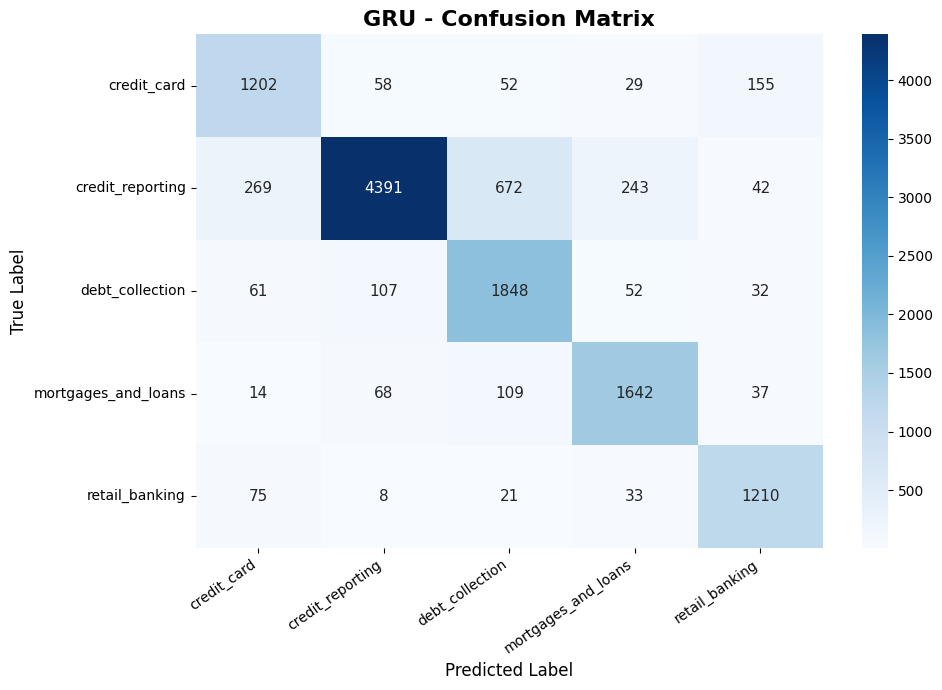

In [46]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate confusion matrix
cm = confusion_matrix(y_val, gru_val_preds)

# Plot
plt.figure(figsize=(10, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
    annot_kws={"size": 11}
)

plt.title("GRU - Confusion Matrix", fontsize=16, fontweight="bold")
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)

plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

# Save high-resolution figure
plt.savefig(
    "/kaggle/working/GRU_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [47]:

import pandas as pd
import os

comparison_path = "/kaggle/working/artifacts/validation_model_comparison.csv"

gru_result = pd.DataFrame([{
    "Model": "GRU",
    "Validation Accuracy": gru_val_accuracy,
    "Validation Macro F1": gru_val_macro_f1,
    "Training Time (min)": gru_training_time,
    "Checkpoint": "/kaggle/working/artifacts/gru_best.keras"
}])

if os.path.exists(comparison_path):
    comparison_df = pd.read_csv(comparison_path)
    comparison_df = pd.concat(
        [comparison_df, gru_result],
        ignore_index=True
    ).drop_duplicates(subset=["Model"], keep="last")
else:
    comparison_df = gru_result

comparison_df.to_csv(comparison_path, index=False)
display(comparison_df.sort_values("Validation Macro F1", ascending=False))


,Model,Validation Accuracy,Validation Macro F1,Training Time (min),Checkpoint
3,GRU,0.828077,0.820768,0.923073,/kaggle/working/artifacts/gru_best.keras
1,LSTM,0.830410,0.815412,2.378259,/kaggle/working/artifacts/lstm_best.keras
0,SimpleRNN,0.700885,0.693135,2.446933,/kaggle/working/artifacts/simple_rnn_best.keras


In [48]:

import os

artifacts_dir = "/kaggle/working/artifacts"

print("Saved model files:")
for root, dirs, files in os.walk(artifacts_dir):
    for file in files:
        print(os.path.join(root, file))

print("\nModels available in memory:")
for name in ["simple_rnn_model", "lstm_model", "gru_model",
             "best_lstm", "best_gru"]:
    print(name, name in globals())


Saved model files:
/kaggle/working/artifacts/model_comparison.csv
/kaggle/working/artifacts/lstm_best.keras
/kaggle/working/artifacts/validation_model_comparison.csv
/kaggle/working/artifacts/simple_rnn_best.keras
/kaggle/working/artifacts/gru_best.keras

Models available in memory:
simple_rnn_model True
lstm_model True
gru_model True
best_lstm True
best_gru True


**Fine-Tuning Transformer (DistilBERT)**

In [7]:

import os
import pandas as pd

base_path = "/kaggle/working"

for name in ["train.csv", "val.csv", "test.csv"]:
    path = os.path.join(base_path, name)
    print(name, "FOUND" if os.path.isfile(path) else "MISSING")

if all(
    os.path.isfile(os.path.join(base_path, name))
    for name in ["train.csv", "val.csv", "test.csv"]
):
    train_df = pd.read_csv(f"{base_path}/train.csv")
    val_df = pd.read_csv(f"{base_path}/val.csv")
    test_df = pd.read_csv(f"{base_path}/test.csv")

    print("\nTraining:", train_df.shape)
    print("Validation:", val_df.shape)
    print("Testing:", test_df.shape)


train.csv FOUND
val.csv FOUND
test.csv FOUND

Training: (99440, 3)
Validation: (12430, 3)
Testing: (12430, 3)


In [8]:

import numpy as np
from sklearn.utils.class_weight import compute_class_weight

y_train = train_df["label"].to_numpy()
y_val = val_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()

classes = np.sort(np.unique(y_train))
num_classes = len(classes)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(label): float(weight)
    for label, weight in zip(classes, weights)
}

print("Number of classes:", num_classes)
print("Class weights:", class_weights)

print("\nLabel Mapping:")
print(
    train_df[["label", "product"]]
    .drop_duplicates()
    .sort_values("label")
    .to_string(index=False)
)


Number of classes: 5
Class weights: {0: 1.6614870509607351, 1: 0.44256531220793094, 2: 1.1839504702940826, 3: 1.329322906222846, 4: 1.8460967232897056}

Label Mapping:
 label             product
     0         credit_card
     1    credit_reporting
     2     debt_collection
     3 mortgages_and_loans
     4      retail_banking


In [9]:

import os
import time
import json
import gc
import numpy as np
import pandas as pd
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

MODEL_NAME = "distilbert/distilbert-base-uncased"
MAX_TRANSFORMER_LEN = 256

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Free unused GPU memory
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Load pretrained tokenizer
hf_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Load pretrained model
transformer_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_classes,
    id2label={
        int(label): product
        for label, product in
        train_df[["label", "product"]]
        .drop_duplicates()
        .itertuples(index=False, name=None)
    },
    label2id={
        product: int(label)
        for label, product in
        train_df[["label", "product"]]
        .drop_duplicates()
        .itertuples(index=False, name=None)
    }
)

transformer_model.to(DEVICE)

print("Model loaded successfully!")
print("Device:", DEVICE)
print("Number of classes:", num_classes)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded successfully!
Device: cuda
Number of classes: 5


In [10]:

from torch.utils.data import Dataset, DataLoader
from transformers import DataCollatorWithPadding

class ComplaintDataset(Dataset):

    def __init__(self, texts, labels, tokenizer):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tokenizer = tokenizer

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.texts[idx],
            truncation=True,
            max_length=MAX_TRANSFORMER_LEN
        )
        encoding["labels"] = int(self.labels[idx])
        return encoding

train_dataset = ComplaintDataset(
    train_df["narrative"].astype(str).tolist(),
    y_train,
    hf_tokenizer
)

val_dataset = ComplaintDataset(
    val_df["narrative"].astype(str).tolist(),
    y_val,
    hf_tokenizer
)

collator = DataCollatorWithPadding(
    tokenizer=hf_tokenizer,
    return_tensors="pt"
)

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    collate_fn=collator,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    collate_fn=collator,
    num_workers=0
)

print("Train samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))


Train samples: 99440
Validation samples: 12430
Train batches: 12430
Validation batches: 777


In [11]:

import math
from transformers import get_linear_schedule_with_warmup

TRANSFORMER_EPOCHS = 3
ACCUMULATION_STEPS = 2
LEARNING_RATE = 2e-5

weights = torch.tensor(
    [class_weights[i] for i in range(num_classes)],
    dtype=torch.float32,
    device=DEVICE
)

criterion = torch.nn.CrossEntropyLoss(weight=weights)

optimizer = torch.optim.AdamW(
    transformer_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.01
)

steps_per_epoch = math.ceil(
    len(train_loader) / ACCUMULATION_STEPS
)

total_steps = steps_per_epoch * TRANSFORMER_EPOCHS

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(total_steps * 0.1),
    num_training_steps=total_steps
)

use_amp = DEVICE.type == "cuda"

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_amp
)

print("Effective batch size:",
      train_loader.batch_size * ACCUMULATION_STEPS)
print("Total optimization steps:", total_steps)
print("Mixed Precision:", use_amp)


Effective batch size: 16
Total optimization steps: 18645
Mixed Precision: True


In [12]:

from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score

BEST_DIR = "/kaggle/working/artifacts/transformer_best"
os.makedirs(BEST_DIR, exist_ok=True)

best_f1 = -1.0
transformer_history = []
start_time = time.time()

for epoch in range(TRANSFORMER_EPOCHS):

    transformer_model.train()
    optimizer.zero_grad(set_to_none=True)

    total_loss = 0.0

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{TRANSFORMER_EPOCHS}"
    )

    for step, batch in enumerate(progress):

        batch = {
            k: v.to(DEVICE)
            for k, v in batch.items()
        }

        with torch.autocast(
            device_type=DEVICE.type,
            enabled=use_amp
        ):
            outputs = transformer_model(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"]
            )

            raw_loss = criterion(
                outputs.logits,
                batch["labels"]
            )

            loss = raw_loss / ACCUMULATION_STEPS

        scaler.scale(loss).backward()

        # Update after accumulation
        if (
            (step + 1) % ACCUMULATION_STEPS == 0
            or (step + 1) == len(train_loader)
        ):

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                transformer_model.parameters(), 1.0
            )

            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

            optimizer.zero_grad(set_to_none=True)

        total_loss += raw_loss.item()

    avg_train_loss = total_loss / len(train_loader)

    # Validation
    transformer_model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for batch in tqdm(val_loader, desc="Validation"):

            batch = {
                k: v.to(DEVICE)
                for k, v in batch.items()
            }

            with torch.autocast(
                device_type=DEVICE.type,
                enabled=use_amp
            ):
                outputs = transformer_model(
                    input_ids=batch["input_ids"],
                    attention_mask=batch["attention_mask"]
                )

            preds = torch.argmax(outputs.logits, dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(batch["labels"].cpu().numpy())

    val_acc = accuracy_score(all_labels, all_preds)
    val_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro",
        zero_division=0
    )

    transformer_history.append({
        "epoch": epoch + 1,
        "train_loss": avg_train_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1
    })

    print(
        f"Epoch {epoch+1} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Accuracy: {val_acc:.4f} | "
        f"Val Macro-F1: {val_f1:.4f}"
    )

    if val_f1 > best_f1:
        best_f1 = val_f1

        transformer_model.save_pretrained(
            BEST_DIR,
            safe_serialization=True
        )
        hf_tokenizer.save_pretrained(BEST_DIR)

        print("Best Transformer saved!")

    pd.DataFrame(transformer_history).to_csv(
        "/kaggle/working/artifacts/transformer_history.csv",
        index=False
    )

transformer_training_time = (
    time.time() - start_time
) / 60

print("\nTraining Completed!")
print("Best Validation Macro-F1:", round(best_f1, 4))
print("Training Time (min):", round(transformer_training_time, 2))


Epoch 1/3:   0%|          | 0/12430 [00:00<?, ?it/s]

Validation:   0%|          | 0/777 [00:00<?, ?it/s]

Epoch 1 | Train Loss: 0.5957 | Val Accuracy: 0.8558 | Val Macro-F1: 0.8449


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best Transformer saved!


Epoch 2/3:   0%|          | 0/12430 [00:00<?, ?it/s]

... (5 outputs left out)

Validation:   0%|          | 0/777 [00:00<?, ?it/s]

Epoch 3 | Train Loss: 0.2960 | Val Accuracy: 0.8670 | Val Macro-F1: 0.8567


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best Transformer saved!

Training Completed!
Best Validation Macro-F1: 0.8567
Training Time (min): 36.74


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Validation Evaluation:   0%|          | 0/777 [00:00<?, ?it/s]


Classification Report:
                     precision    recall  f1-score   support

        credit_card       0.79      0.85      0.82      1496
   credit_reporting       0.92      0.87      0.90      5617
    debt_collection       0.80      0.84      0.82      2100
mortgages_and_loans       0.84      0.88      0.86      1870
     retail_banking       0.88      0.90      0.89      1347

           accuracy                           0.87     12430
          macro avg       0.85      0.87      0.86     12430
       weighted avg       0.87      0.87      0.87     12430



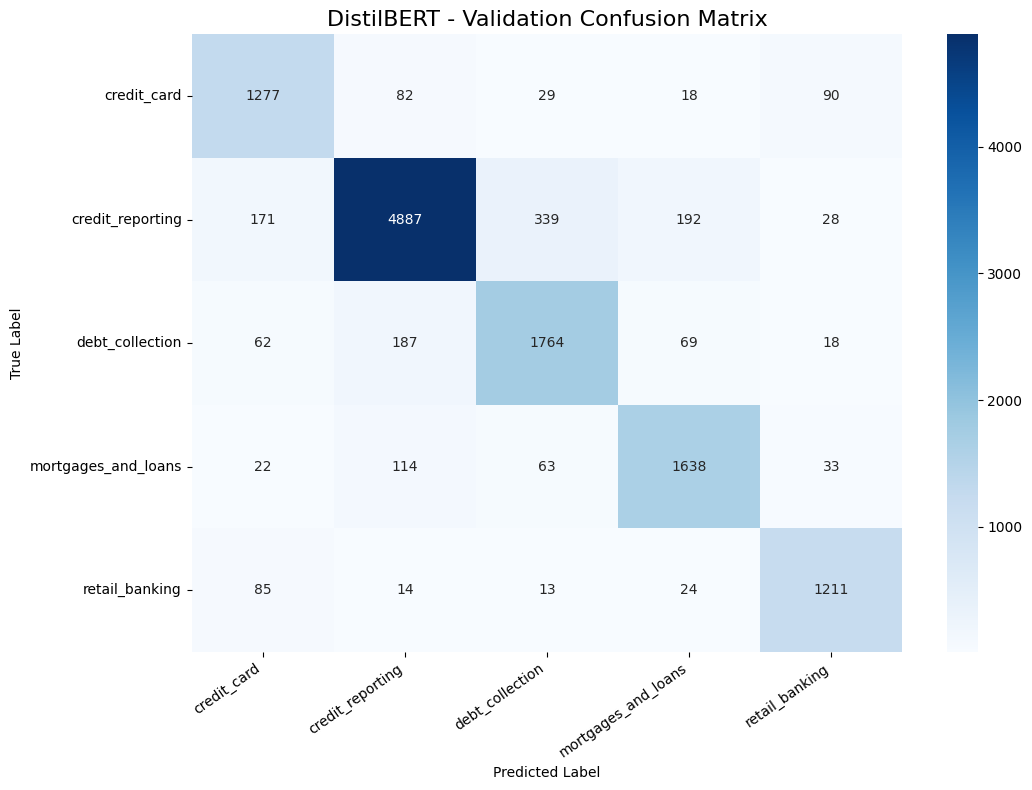

In [13]:

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.auto import tqdm
from transformers import AutoModelForSequenceClassification
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

BEST_DIR = "/kaggle/working/artifacts/transformer_best"

best_transformer = AutoModelForSequenceClassification.from_pretrained(
    BEST_DIR
).to(DEVICE)

best_transformer.eval()

transformer_val_preds = []
transformer_val_labels = []

with torch.no_grad():
    for batch in tqdm(val_loader, desc="Validation Evaluation"):

        batch = {
            k: v.to(DEVICE)
            for k, v in batch.items()
        }

        outputs = best_transformer(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"]
        )

        preds = torch.argmax(outputs.logits, dim=1)

        transformer_val_preds.extend(preds.cpu().numpy())
        transformer_val_labels.extend(batch["labels"].cpu().numpy())

print("\nClassification Report:")
print(
    classification_report(
        transformer_val_labels,
        transformer_val_preds,
        target_names=[
            "credit_card",
            "credit_reporting",
            "debt_collection",
            "mortgages_and_loans",
            "retail_banking"
        ],
        zero_division=0
    )
)

cm = confusion_matrix(
    transformer_val_labels,
    transformer_val_preds
)

class_names = [
    "credit_card",
    "credit_reporting",
    "debt_collection",
    "mortgages_and_loans",
    "retail_banking"
]

plt.figure(figsize=(11, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("DistilBERT - Validation Confusion Matrix", fontsize=16)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/artifacts/transformer_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [14]:

import shutil
from IPython.display import FileLink, display

zip_path = shutil.make_archive(
    "/kaggle/working/transformer_best",
    "zip",
    "/kaggle/working/artifacts/transformer_best"
)

print("Saved:", zip_path)
display(FileLink(zip_path))


Saved: /kaggle/working/transformer_best.zip


/kaggle/working/transformer_best.zip

**Final Test Evaluation & Model Comparison**

In [24]:

import os
import gc
import pickle
import numpy as np
import pandas as pd

ARTIFACTS = "/kaggle/working/artifacts"
TEST_PATH = "/kaggle/working/test.csv"
TRAIN_PATH = "/kaggle/working/train.csv"
TOKENIZER_PATH = f"{ARTIFACTS}/tokenizer.pkl"
TRANSFORMER_DIR = f"{ARTIFACTS}/transformer_best"

MODEL_PATHS = {
    "SimpleRNN": f"{ARTIFACTS}/simple_rnn_best.keras",
    "LSTM": f"{ARTIFACTS}/lstm_best.keras",
    "GRU": f"{ARTIFACTS}/gru_best.keras"
}

required_files = [
    TRAIN_PATH,
    TEST_PATH,
    TOKENIZER_PATH,
    *MODEL_PATHS.values(),
    f"{TRANSFORMER_DIR}/config.json"
]

for path in required_files:
    if not os.path.isfile(path):
        raise FileNotFoundError(f"Missing: {path}")

if not any(
    os.path.isfile(f"{TRANSFORMER_DIR}/{name}")
    for name in ["model.safetensors", "pytorch_model.bin"]
):
    raise FileNotFoundError("Transformer weights not found")

# Load original datasets
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

# Restore tokenizer
with open(TOKENIZER_PATH, "rb") as f:
    keras_tokenizer = pickle.load(f)

# Original label mapping
class_names = [
    "credit_card",
    "credit_reporting",
    "debt_collection",
    "mortgages_and_loans",
    "retail_banking"
]

assert len(test_df) == 12430
assert test_df["label"].between(0, 4).all()

y_test = test_df["label"].to_numpy()

# Check label mapping
mapping = (
    train_df[["label", "product"]]
    .drop_duplicates()
    .sort_values("label")
)

assert mapping["product"].tolist() == class_names

# Verify tokenizer configuration
assert keras_tokenizer.num_words == 20000
assert keras_tokenizer.oov_token == "<OOV>"

print("All required artifacts found!")
print("Test Samples:", len(test_df))
print("Classes:", len(class_names))
print("Vocabulary:", len(keras_tokenizer.word_index))

print("\nModel Files:")
for name, path in MODEL_PATHS.items():
    print(name, "READY")

print("DistilBERT READY")


All required artifacts found!
Test Samples: 12430
Classes: 5
Vocabulary: 41669

Model Files:
SimpleRNN READY
LSTM READY
GRU READY
DistilBERT READY


In [25]:

import tensorflow as tf
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Prepare Keras input
X_test_sequences = keras_tokenizer.texts_to_sequences(
    test_df["narrative"].astype(str).tolist()
)

X_test_padded = pad_sequences(
    X_test_sequences,
    maxlen=240,
    padding="post",
    truncating="post"
)

print("Keras Test Shape:", X_test_padded.shape)

# Store predictions for all models
all_predictions = {}

for name, path in MODEL_PATHS.items():

    print(f"\nEvaluating {name}...")

    tf.keras.backend.clear_session()

    with tf.device("/CPU:0"):
        model = tf.keras.models.load_model(
            path,
            compile=False
        )

        probabilities = model.predict(
            X_test_padded,
            batch_size=128,
            verbose=1
        )

    all_predictions[name] = np.argmax(
        probabilities,
        axis=1
    )

    print(f"{name} completed!")

    del model, probabilities
    gc.collect()

tf.keras.backend.clear_session()

print("\nAll Keras models evaluated!")


Keras Test Shape: (12430, 240)

Evaluating SimpleRNN...
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step
SimpleRNN completed!

Evaluating LSTM...
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
LSTM completed!

Evaluating GRU...
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step
GRU completed!

All Keras models evaluated!


In [26]:

import torch
from torch.utils.data import Dataset, DataLoader

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding
)

from tqdm.auto import tqdm

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Load saved Hugging Face artifacts
hf_tokenizer = AutoTokenizer.from_pretrained(
    TRANSFORMER_DIR
)

transformer = AutoModelForSequenceClassification.from_pretrained(
    TRANSFORMER_DIR
).to(DEVICE)

class TransformerTestDataset(Dataset):

    def __init__(self, texts, tokenizer):
        self.texts = list(texts)
        self.tokenizer = tokenizer

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        return self.tokenizer(
            self.texts[idx],
            truncation=True,
            max_length=256
        )

test_dataset = TransformerTestDataset(
    test_df["narrative"].astype(str).tolist(),
    hf_tokenizer
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    collate_fn=DataCollatorWithPadding(
        tokenizer=hf_tokenizer,
        return_tensors="pt"
    ),
    num_workers=0
)

transformer.eval()
predictions = []

with torch.inference_mode():

    for batch in tqdm(test_loader, desc="DistilBERT"):

        batch = {
            k: v.to(DEVICE)
            for k, v in batch.items()
        }

        outputs = transformer(**batch)

        predictions.extend(
            outputs.logits.argmax(dim=1)
            .cpu().numpy()
        )

all_predictions["DistilBERT"] = np.array(predictions)

print("DistilBERT evaluation completed!")

# Release memory
transformer.cpu()
del transformer
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

DistilBERT:   0%|          | 0/777 [00:00<?, ?it/s]

DistilBERT evaluation completed!


In [27]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

final_results = []

for name, predictions in all_predictions.items():

    assert len(predictions) == len(y_test)

    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions,
            average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions,
            average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, predictions,
            average="macro", zero_division=0
        )
    }

    final_results.append(metrics)

    print(f"\n{'=' * 50}")
    print(f"{name} - Classification Report")
    print("=" * 50)

    print(classification_report(
        y_test,
        predictions,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        zero_division=0
    ))

final_results_df = pd.DataFrame(final_results)

# Keep original model order
display(final_results_df.round(4))

final_results_df.to_csv(
    f"{ARTIFACTS}/final_test_results.csv",
    index=False
)

print("Results saved successfully!")



SimpleRNN - Classification Report
                     precision    recall  f1-score   support

        credit_card       0.58      0.68      0.62      1497
   credit_reporting       0.87      0.63      0.73      5617
    debt_collection       0.50      0.73      0.59      2100
mortgages_and_loans       0.70      0.83      0.76      1870
     retail_banking       0.72      0.74      0.73      1346

           accuracy                           0.69     12430
          macro avg       0.67      0.72      0.69     12430
       weighted avg       0.73      0.69      0.70     12430


LSTM - Classification Report
                     precision    recall  f1-score   support

        credit_card       0.73      0.79      0.76      1497
   credit_reporting       0.92      0.82      0.87      5617
    debt_collection       0.73      0.81      0.77      2100
mortgages_and_loans       0.80      0.84      0.82      1870
     retail_banking       0.81      0.88      0.84      1346

           accu

,Model,Accuracy,Precision,Recall,Macro F1
0,SimpleRNN,0.6926,0.6746,0.7207,0.6875
1,LSTM,0.8283,0.7991,0.8316,0.8137
2,GRU,0.8224,0.7981,0.8429,0.8160
3,DistilBERT,0.8616,0.8407,0.8605,0.8501


Results saved successfully!


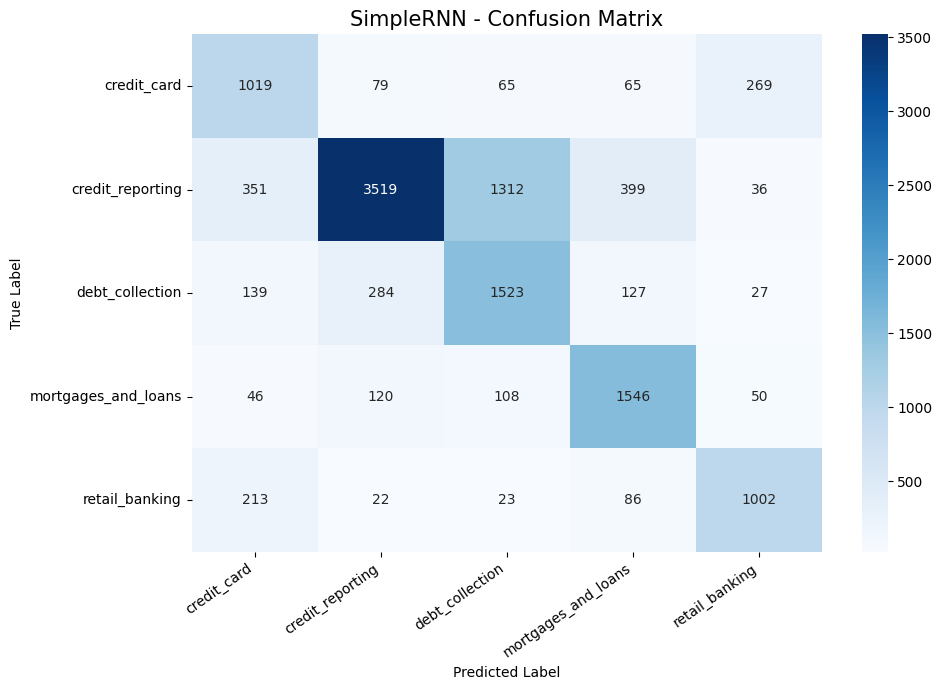

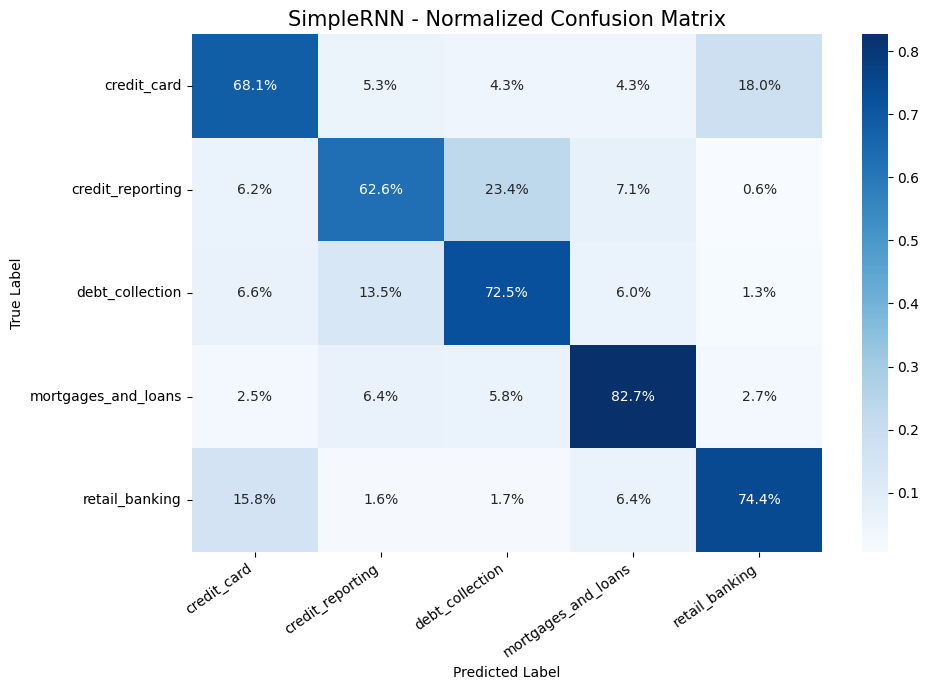

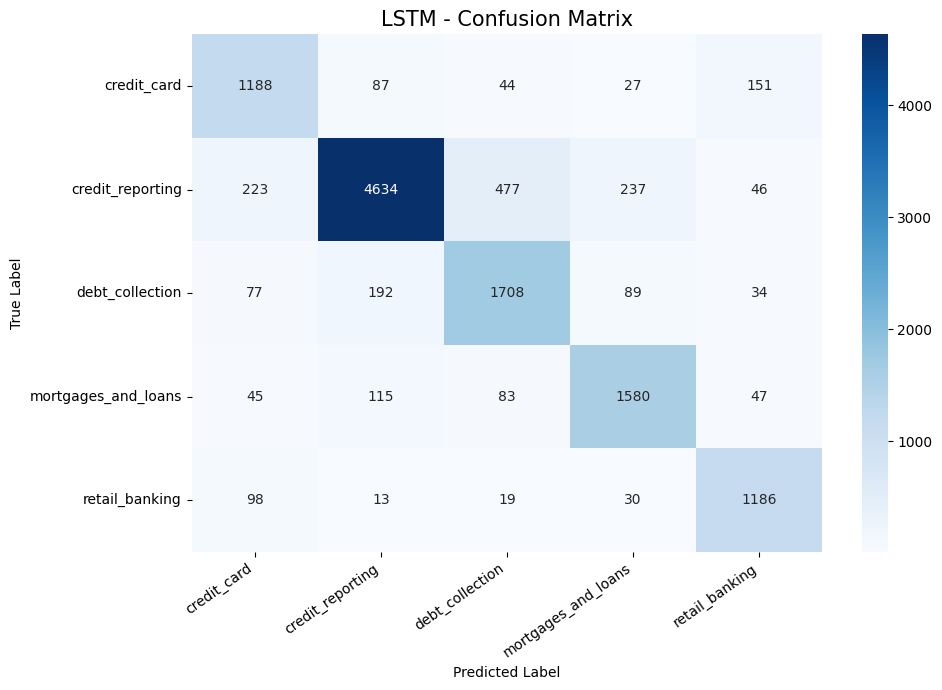

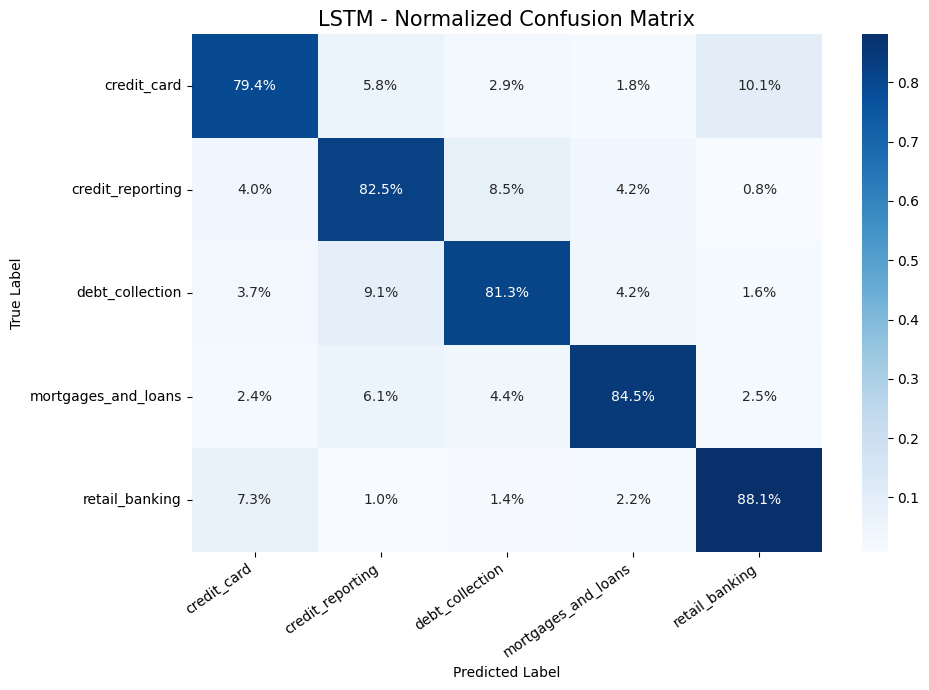

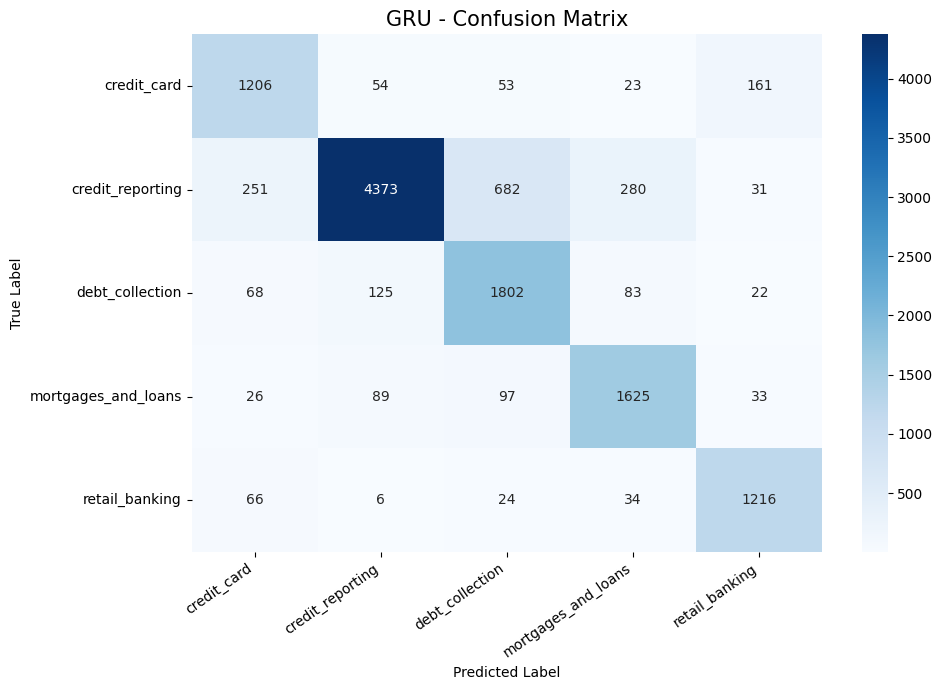

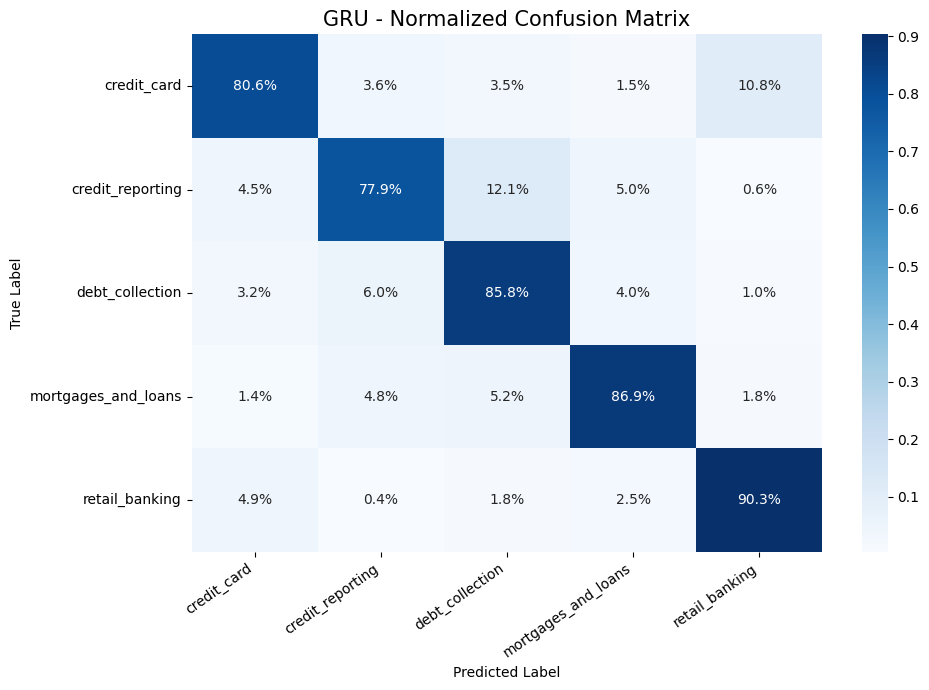

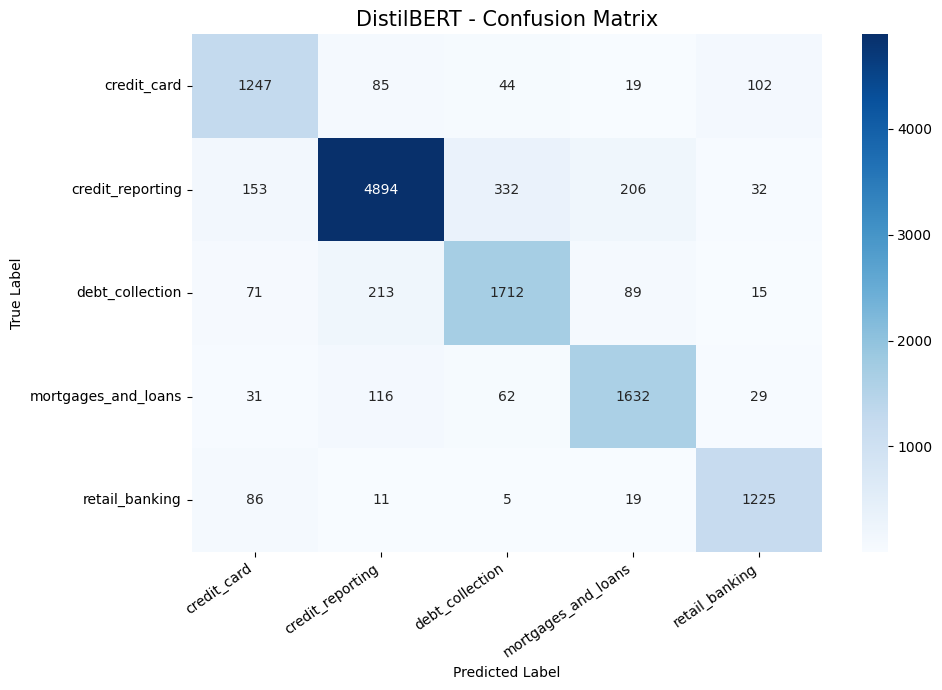

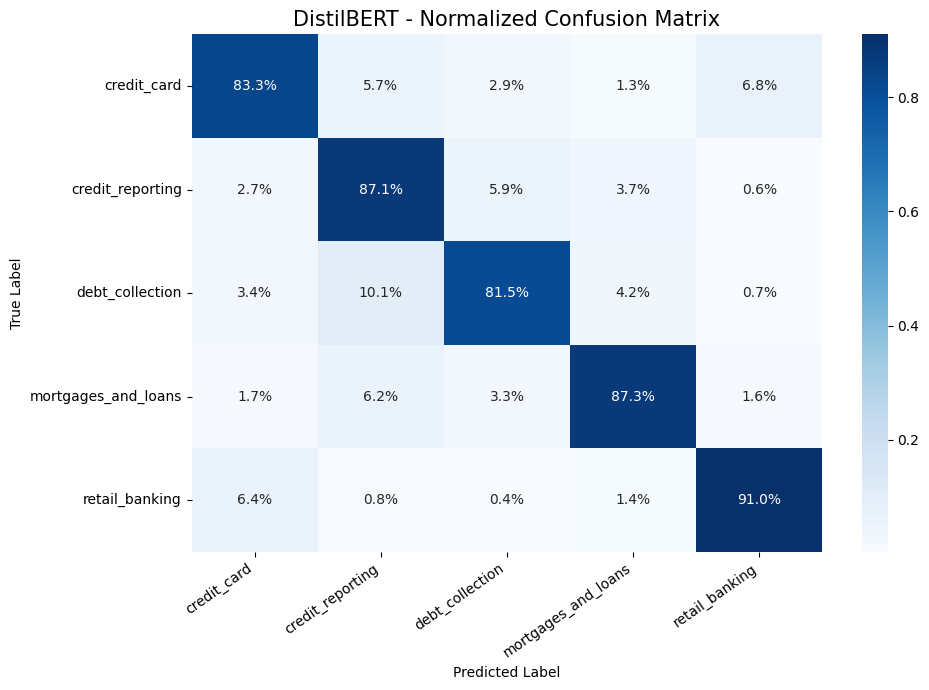

In [28]:

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

for name, predictions in all_predictions.items():

    for normalized in [False, True]:

        cm = confusion_matrix(
            y_test,
            predictions,
            labels=np.arange(len(class_names)),
            normalize="true" if normalized else None
        )

        plt.figure(figsize=(10, 7))

        sns.heatmap(
            cm,
            annot=True,
            fmt=".1%" if normalized else "d",
            cmap="Blues",
            xticklabels=class_names,
            yticklabels=class_names
        )

        title = (
            f"{name} - Normalized Confusion Matrix"
            if normalized
            else f"{name} - Confusion Matrix"
        )

        plt.title(title, fontsize=15)
        plt.xlabel("Predicted Label")
        plt.ylabel("True Label")
        plt.xticks(rotation=35, ha="right")
        plt.yticks(rotation=0)
        plt.tight_layout()

        filename = (
            f"{name}_normalized_cm.png"
            if normalized
            else f"{name}_confusion_matrix.png"
        )

        plt.savefig(
            f"{ARTIFACTS}/{filename}",
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()


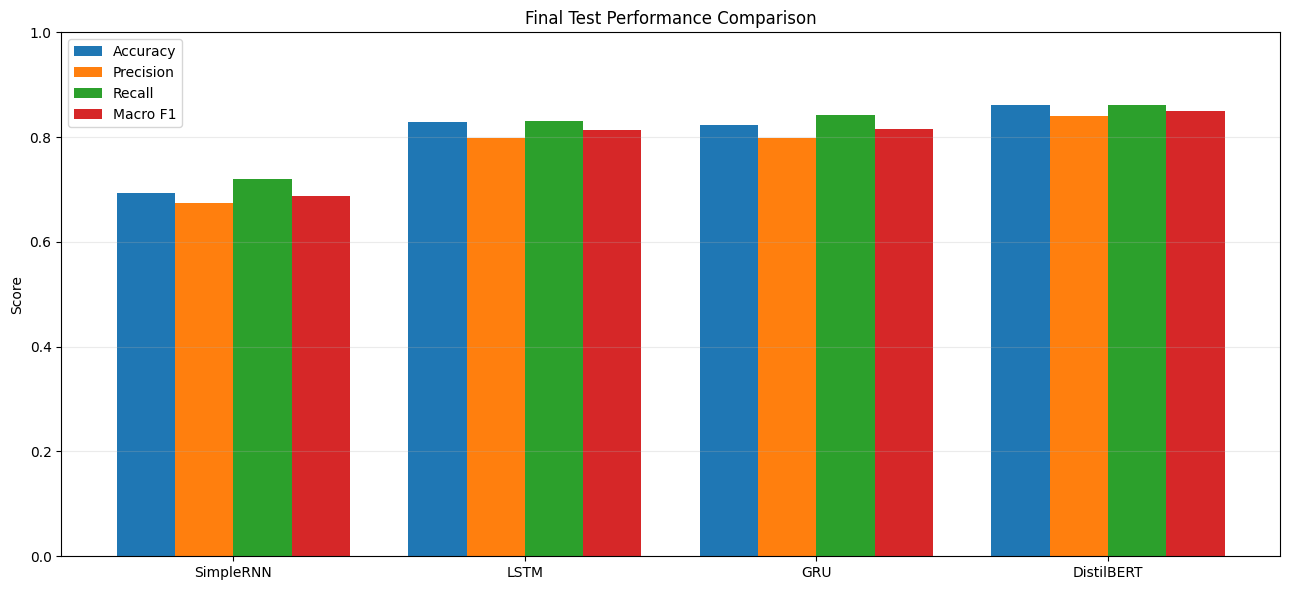

In [29]:

import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy", "Precision", "Recall", "Macro F1"]

x = np.arange(len(final_results_df))
width = 0.20

fig, ax = plt.subplots(figsize=(13, 6))

for i, metric in enumerate(metrics):
    ax.bar(
        x + (i - 1.5) * width,
        final_results_df[metric],
        width,
        label=metric
    )

ax.set_xticks(x)
ax.set_xticklabels(final_results_df["Model"])

ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Final Test Performance Comparison")
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    f"{ARTIFACTS}/final_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


**Gradio**

In [ ]:

import os
import torch
import gradio as gr

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

# ==========================================
# 1. LOAD SAVED MODEL
# ==========================================

MODEL_PATH = "/kaggle/working/artifacts/transformer_best"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_PATH
).to(device)

model.eval()

print("DistilBERT loaded successfully!")


# ==========================================
# 2. PREDICTION FUNCTION
# ==========================================

def predict_complaint(text):

    if not text or not text.strip():
        return "", "", {}

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=256
    ).to(device)

    with torch.inference_mode():
        outputs = model(**inputs)

        probabilities = torch.softmax(
            outputs.logits,
            dim=-1
        )[0].cpu().numpy()

    predicted_id = int(probabilities.argmax())

    labels = model.config.id2label

    predicted_category = labels[
        predicted_id
    ].replace("_", " ").title()

    confidence = float(probabilities[predicted_id])

    scores = {
        labels[i].replace("_", " ").title(): float(score)
        for i, score in enumerate(probabilities)
    }

    return (
        predicted_category,
        f"{confidence:.2%}",
        scores
    )


# ==========================================
# 3. DARK THEME
# ==========================================

dark_theme = gr.themes.Base(
    primary_hue="violet",
    secondary_hue="blue",
    neutral_hue="slate"
).set(
    body_background_fill="#09090f",
    body_background_fill_dark="#09090f",

    block_background_fill="#181825",
    block_background_fill_dark="#181825",

    block_border_color="#303044",
    block_border_color_dark="#303044",

    input_background_fill="#11111b",
    input_background_fill_dark="#11111b",

    button_primary_background_fill="#7c3aed",
    button_primary_background_fill_hover="#6d28d9",
    button_primary_text_color="#ffffff",

    body_text_color="#f8fafc",
    body_text_color_dark="#f8fafc"
)


# ==========================================
# 4. CUSTOM CSS
# ==========================================

custom_css = """
.gradio-container {
    max-width: 1150px !important;
    margin: auto !important;
    background: #09090f !important;
}

body {
    background: #09090f !important;
}

h1 {
    text-align: center;
    color: #f8fafc !important;
    font-size: 36px !important;
    font-weight: 800 !important;
}

.subtitle {
    text-align: center;
    color: #a1a1aa !important;
    margin-bottom: 30px;
    font-size: 15px;
}

#classify-btn {
    background: linear-gradient(
        90deg, #7c3aed, #2563eb
    ) !important;
    color: white !important;
    border: none !important;
    border-radius: 12px !important;
    font-weight: 700 !important;
    min-height: 46px;
}

#classify-btn:hover {
    background: linear-gradient(
        90deg, #6d28d9, #1d4ed8
    ) !important;
}

#prediction-card {
    border: 1px solid #303044;
    border-radius: 14px;
}

footer {
    display: none !important;
}
"""


# ==========================================
# 5. BUILD GRADIO INTERFACE
# ==========================================

with gr.Blocks(
    theme=dark_theme,
    css=custom_css,
    title="Consumer Complaint Classifier"
) as demo:

    gr.Markdown(
        """
        # Consumer Complaint Classifier

        <p class="subtitle">
        AI-Powered Customer Complaint Classification
        using Fine-Tuned DistilBERT
        </p>
        """
    )

    with gr.Row(equal_height=True):

        # Input Section
        with gr.Column(scale=3):

            gr.Markdown("### Customer Complaint")

            complaint_input = gr.Textbox(
                label="Enter Complaint Narrative",
                placeholder=(
                    "Describe the customer's complaint here..."
                ),
                lines=8
            )

            classify_btn = gr.Button(
                "Classify Complaint",
                variant="primary",
                elem_id="classify-btn"
            )

            clear_btn = gr.Button(
                "Clear",
                variant="secondary"
            )

        # Prediction Section
        with gr.Column(
            scale=2,
            elem_id="prediction-card"
        ):

            gr.Markdown("### Classification Results")

            predicted_category = gr.Textbox(
                label="Predicted Complaint Category",
                interactive=False
            )

            confidence_score = gr.Textbox(
                label="Confidence Score",
                interactive=False
            )

            prediction_output = gr.Label(
                label="All Category Probabilities",
                num_top_classes=5
            )

    # ======================================
    # 6. BUTTON EVENTS
    # ======================================

    classify_btn.click(
        fn=predict_complaint,
        inputs=complaint_input,
        outputs=[
            predicted_category,
            confidence_score,
            prediction_output
        ]
    )

    clear_btn.click(
        fn=lambda: ("", "", "", {}),
        inputs=[],
        outputs=[
            complaint_input,
            predicted_category,
            confidence_score,
            prediction_output
        ]
    )

    # ======================================
    # 7. EXAMPLE COMPLAINTS
    # ======================================

    gr.Markdown("### Try Example Complaints")

    gr.Examples(
        examples=[
            [
                "My credit card was charged twice "
                "and the bank refused to refund me."
            ],
            [
                "My credit report contains incorrect "
                "payment history and inaccurate information."
            ],
            [
                "A debt collector keeps calling me "
                "about a debt I do not owe."
            ],
            [
                "My mortgage company charged unexpected "
                "fees on my home loan."
            ],
            [
                "My checking account was frozen "
                "without any explanation."
            ]
        ],
        inputs=complaint_input
    )

    # ======================================
    # 8. FOOTER
    # ======================================

    gr.Markdown(
        """
        ---

        **Consumer Complaint Classification — Deep Learning NLP Project**

        Models Compared: SimpleRNN | LSTM | GRU | DistilBERT

        **Final Model:** Fine-Tuned DistilBERT

        *Confidence scores represent model probabilities,
        not guaranteed prediction accuracy.*
        """
    )


# ==========================================
# 9. LAUNCH APPLICATION
# ==========================================

demo.launch(
    share=True,
    debug=True,
    show_error=True
)


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

DistilBERT loaded successfully!


/tmp/ipykernel_1355/443293963.py:168: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


* Running on local URL:  http://127.0.0.1:7861
* Running on public URL: https://3aea44fa8edff85523.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
